# EGH455 — YOLOv5s valve/gauge training (real dataset)

Roboflow `egh455-epcw7-vi0yr` **v3 "real-data-v2 (gauge split fix)"** → strip Fire-extinguisher → train YOLOv5s 640×640 → ONNX → OAK-D `.blob`.

Final classes (order must match `detect_oakd.py` `LABELS`): `valve_open`, `valve_closed`, `gauge`.

Runtime → Change runtime type → **GPU** before running.

In [ ]:
!nvidia-smi

Sat Oct 10 12:57:52 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   40C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
%cd /content
!git clone https://github.com/ultralytics/yolov5
%cd /content/yolov5
!pip install -q -r requirements.txt roboflow

/content
Cloning into 'yolov5'...
remote: Enumerating objects: 18770, done.
remote: Counting objects: 100% (327/327), done.
remote: Compressing objects: 100% (199/199), done.
remote: Total 18770 (delta 264), reused 128 (delta 128), pack-reused 18443 (from 5)
Receiving objects: 100% (18770/18770), 17.83 MiB | 18.27 MiB/s, done.
Resolving deltas: 100% (12769/12769), done.
/content/yolov5
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 373.9/373.9 kB 17.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 63.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 136.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 6.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 10.8 MB/s eta 0:00:00


## Download dataset v3
Paste your Roboflow auth token when prompted (don't hard-code an API key in the notebook).

In [9]:
import roboflow
roboflow.login()
rf = roboflow.Roboflow()
project = rf.workspace("n11470941-qut-edu-au").project("egh455-epcw7-vi0yr")
dataset = project.version(3).download("yolov5")
print(dataset.location)

You are already logged into Roboflow. To make a different login,run roboflow.login(force=True).
loading Roboflow workspace...
loading Roboflow project...
Exporting format yolov5pytorch in progress : 95.0%
Version export complete for yolov5pytorch format



Extracting Dataset Version Zip to EGH455-3 in yolov5pytorch:: 100%|██████████| 8065/8065 [00:03<00:00, 2358.90it/s]

/content/yolov5/EGH455-3


## Strip Fire-extinguisher → 3 classes
Same script as `~/egh455_pi_deploy/strip_classes.py`. Maps by class name, so Roboflow's index order doesn't matter.

In [10]:
%%writefile /content/yolov5/strip_classes.py
"""Turn the 4-class Roboflow YOLOv5 export into the 3-class training set.

Run in Colab after downloading the Roboflow version, before train.py:
    python strip_classes.py /content/<dataset_dir>

Drops Fire-extinguisher boxes and remaps the rest to the order detect_oakd.py
expects (LABELS = ["valve_open", "valve_closed", "gauge"]). Class mapping is by
name from data.yaml, so it doesn't depend on Roboflow's index order.
Images that end up with no boxes stay as negatives (empty label file).
"""
import sys
from pathlib import Path

RENAME = {"Valve Open": "valve_open", "Valve Close": "valve_closed", "Gauge": "gauge"}
TARGET = ["valve_open", "valve_closed", "gauge"]


def remap_lines(lines, old_names):
    out = []
    for line in lines:
        parts = line.split()
        if not parts:
            continue
        new = RENAME.get(old_names[int(parts[0])])
        if new is not None:
            out.append(" ".join([str(TARGET.index(new))] + parts[1:]))
    return out


def main(root):
    import yaml  # installed with YOLOv5's requirements in Colab

    root = Path(root)
    cfg = yaml.safe_load((root / "data.yaml").read_text())
    old_names = cfg["names"]
    unknown = set(old_names) - set(RENAME) - {"Fire-extinguisher"}
    if unknown:
        sys.exit(f"Unexpected classes in data.yaml: {unknown}")

    files = list(root.glob("*/labels/*.txt"))
    for f in files:
        f.write_text("\n".join(remap_lines(f.read_text().splitlines(), old_names)))

    cfg["names"], cfg["nc"] = TARGET, len(TARGET)
    (root / "data.yaml").write_text(yaml.safe_dump(cfg, sort_keys=False))
    print(f"Remapped {len(files)} label files -> {TARGET}")


if __name__ == "__main__":
    if len(sys.argv) == 2:
        main(sys.argv[1])
    else:  # self-check
        names = ["Fire-extinguisher", "Gauge", "Valve Close", "Valve Open"]
        got = remap_lines(["0 .5 .5 .1 .1", "1 .2 .2 .1 .1", "2 .3 .3 .1 .1", "3 .4 .4 .1 .1"], names)
        assert got == ["2 .2 .2 .1 .1", "1 .3 .3 .1 .1", "0 .4 .4 .1 .1"], got
        print("self-check ok")


Overwriting /content/yolov5/strip_classes.py


In [11]:
!python strip_classes.py {dataset.location}
!cat {dataset.location}/data.yaml

Remapped 4030 label files -> ['valve_open', 'valve_closed', 'gauge']
names:
- valve_open
- valve_closed
- gauge
nc: 3
roboflow:
  license: CC BY 4.0
  project: egh455-epcw7-vi0yr
  url: https://universe.roboflow.com/n11470941-qut-edu-au/egh455-epcw7-vi0yr/dataset/3
  version: 3
  workspace: n11470941-qut-edu-au
test: ../test/images
train: EGH455-3/train/images
val: EGH455-3/valid/images


In [12]:
# Sanity check: box counts per class after stripping. Expect only 0/1/2, no 3.
from collections import Counter
from pathlib import Path
for split in ["train", "valid", "test"]:
    c = Counter(l.split()[0] for f in Path(dataset.location, split, "labels").glob("*.txt")
                for l in f.read_text().splitlines() if l.strip())
    print(split, {["valve_open", "valve_closed", "gauge"][int(k)]: v for k, v in sorted(c.items())})

train {'valve_open': 702, 'valve_closed': 1347, 'gauge': 723}
valid {'valve_open': 58, 'valve_closed': 118, 'gauge': 54}
test {'valve_open': 29, 'valve_closed': 71, 'gauge': 28}


## Train

In [13]:
%cd /content/yolov5
%env WANDB_MODE=disabled
!rm -rf runs/train/egh455_real  # clear any interrupted run so outputs land in egh455_real
!python train.py --img 640 --batch 16 --epochs 100 --data {dataset.location}/data.yaml --weights yolov5s.pt --name egh455_real --cache

/content/yolov5
env: WANDB_MODE=disabled
WARNING ⚠️ wandb: wandb is deprecated and will be removed in a future release. See supported integrations at https://github.com/ultralytics/yolov5#integrations.
I0000 00:00:1791637962.483525    7880 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
train: weights=yolov5s.pt, cfg=, data=/content/yolov5/EGH455-3/data.yaml, hyp=data/hyps/hyp.scratch-low.yaml, epochs=100, batch_size=16, imgsz=640, rect=False, resume=False, nosave=False, noval=False, noautoanchor=False, noplots=False, evolve=None, evolve_population=data/hyps, resume_evolve=None, bucket=, cache=ram, image_weights=False, device=, multi_scale=False, single_cls=False, optimizer=SGD, sync_bn=False, workers=8, project=runs/train, name=egh455_real, exist_ok=False, quad=False, cos_lr=False, label_smoothing=0.0, patience=100, freeze=[0], save_period=-1, seed=0, local_rank=-1, entity=None, upload_dataset=False, bbox_interval=-1
github: up to date with https:

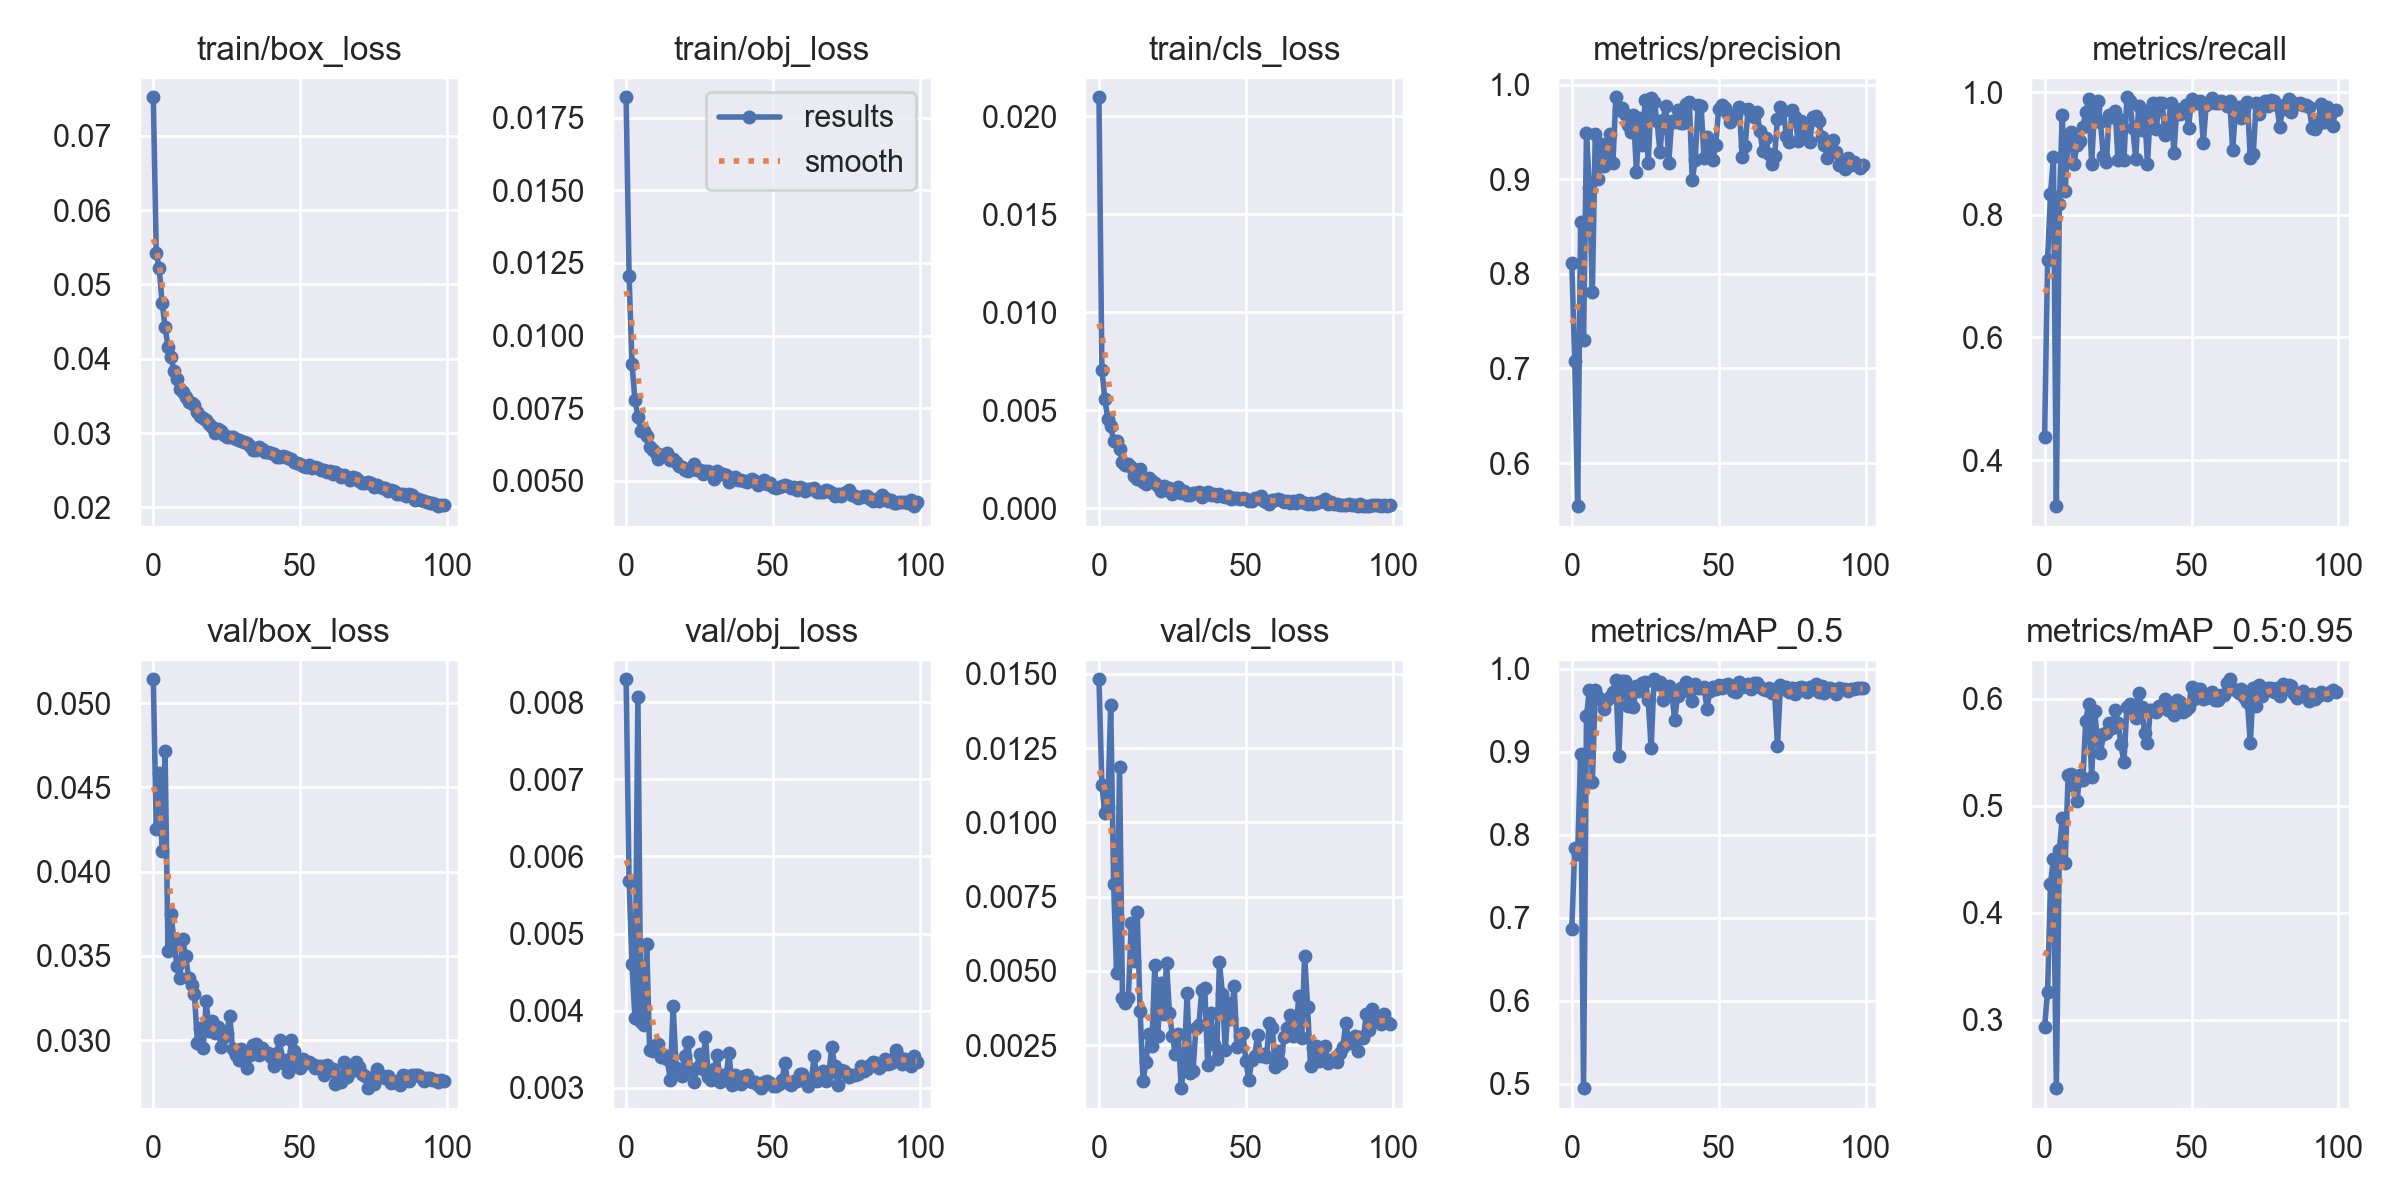

In [14]:
from IPython.display import Image
Image(filename="/content/yolov5/runs/train/egh455_real/results.png", width=1000)

In [15]:
# Anchors baked into best.pt (pixels). detect_oakd.py ANCHORS must match these;
# AutoAnchor can change them if the defaults fit the dataset badly.
import torch
m = torch.load("runs/train/egh455_real/weights/best.pt", map_location="cpu", weights_only=False)["model"].float()
det = m.model[-1]
print((det.anchors * det.stride.view(-1, 1, 1)).flatten().round().int().tolist())

[10, 13, 16, 30, 33, 23, 30, 61, 62, 45, 59, 119, 116, 90, 156, 198, 373, 326]


## Export → ONNX → OAK-D blob

In [16]:
!python export.py --weights runs/train/egh455_real/weights/best.pt --include onnx --imgsz 640 --opset 12

export: data=data/coco128.yaml, weights=['runs/train/egh455_real/weights/best.pt'], imgsz=[640], batch_size=1, device=cpu, half=False, inplace=False, keras=False, optimize=False, int8=False, per_tensor=False, dynamic=False, cache=, simplify=False, mlmodel=False, opset=12, verbose=False, workspace=4, nms=False, agnostic_nms=False, topk_per_class=100, topk_all=100, iou_thres=0.45, conf_thres=0.25, include=['onnx']
YOLOv5 🚀 v7.0-556-gf9578796 Python-3.13.15 torch-2.11.0+cu130 CPU

Fusing layers... 
Model summary: 68 layers, 7,018,216 parameters, 0 gradients, 15.8 GFLOPs

PyTorch: starting from runs/train/egh455_real/weights/best.pt with output shape (1, 25200, 8) (13.8 MB)
requirements: Ultralytics requirement ['onnx>=1.12.0'] not found, attempting AutoUpdate...
Using Python 3.13.15 environment at: /usr
Resolved 5 packages in 279ms
Prepared 1 package in 264ms
Installed 1 package in 40ms
 + onnx==1.23.2

requirements: AutoUpdate success ✅ 0.9s
WARNING ⚠️ requirements: Restart runtime or re

In [17]:
!pip install -q blobconverter
import blobconverter
blob = blobconverter.from_onnx(
    model="runs/train/egh455_real/weights/best.onnx",
    data_type="FP16",
    shaves=6,
    version="2022.1",
    optimizer_params=["--scale=255", "--reverse_input_channel"],
    output_dir="runs/train/egh455_real/weights",
)
print(blob)

[==================================================]
Done
runs/train/egh455_real/weights/best_openvino_2022.1_6shave.blob


In [18]:
from google.colab import files
files.download(str(blob))
files.download("runs/train/egh455_real/weights/best.pt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [19]:
%cd /content/yolov5
!sed -i 's#^test: .*#test: EGH455-3/test/images#' /content/yolov5/EGH455-3/data.yaml
!python val.py --weights runs/train/egh455_real/weights/best.pt --data /content/yolov5/EGH455-3/data.yaml --task test --img 640 --name egh455_real_test

/content/yolov5
val: data=/content/yolov5/EGH455-3/data.yaml, weights=['runs/train/egh455_real/weights/best.pt'], batch_size=32, imgsz=640, conf_thres=0.001, iou_thres=0.6, max_det=300, task=test, device=, workers=8, single_cls=False, augment=False, verbose=False, save_txt=False, save_hybrid=False, save_conf=False, save_json=False, project=runs/val, name=egh455_real_test, exist_ok=False, half=False, dnn=False
YOLOv5 🚀 v7.0-556-gf9578796 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 68 layers, 7,018,216 parameters, 0 gradients, 15.8 GFLOPs
test: Scanning /content/yolov5/EGH455-3/test/labels... 159 images, 32 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 159/159 473.6it/s 0.3s
test: New cache created: /content/yolov5/EGH455-3/test/labels.cache
                 Class     Images  Instances          P          R      mAP50   mAP50-95: 100% ━━━━━━━━━━━━ 5/5 1.2it/s 4.0s
                   all        159        128      0.977      0.994      0.982